In [3]:
import pandas as pd
import numpy as np

# 1. Load the dataset
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')

# 2. Inspect dimensions (rows, columns)
print("Dataset Shape:", df.shape)

# 3. Inspect data types and non-null counts
print("\nData Info:")
print(df.info())

# 4. Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check for duplicate rows
print("\nDuplicate Rows Count:", df.duplicated().sum())

# 6. Clean duplicates (if any)
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Dataset Shape: (1338, 7)

Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate Rows Count: 1
Shape after removing duplicates: (1337, 7)


               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.663452     1.095737  13279.121487
std      14.044333     6.100468     1.205571  12110.359656
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000    53.130000     5.000000  63770.428010


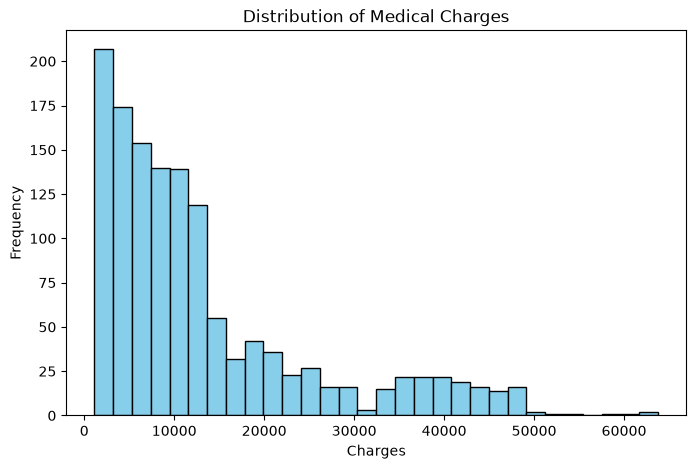

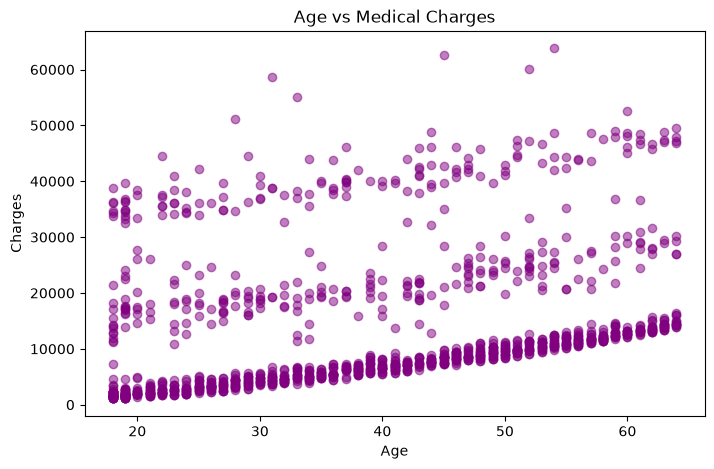


Correlation Matrix:
               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


In [4]:
import matplotlib.pyplot as plt

# 1. Summary statistics for numerical columns
print(df.describe())

# 2. Visualizing distribution of the target variable (charges)
plt.figure(figsize=(8, 5))
plt.hist(df['charges'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Medical Charges')
plt.xlabel('Charges')
plt.ylabel('Frequency')
plt.show()

# 3. Visualizing Age vs Charges
plt.figure(figsize=(8, 5))
plt.scatter(df['age'], df['charges'], alpha=0.5, color='purple')
plt.title('Age vs Medical Charges')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.show()

# 4. Correlation matrix for numerical variables
print("\nCorrelation Matrix:")
print(df[['age', 'bmi', 'children', 'charges']].corr())

In [5]:
from sklearn.model_selection import train_test_split

# 1. Convert categorical columns to numerical values (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# 2. Define Features (X) and Target (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# 3. Split the dataset into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Print shapes to verify
print("Training set shape (X_train):", X_train.shape)
print("Testing set shape (X_test):", X_test.shape)

Training set shape (X_train): (1069, 8)
Testing set shape (X_test): (268, 8)
